In [1]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder,MinMaxScaler,StandardScaler
import seaborn as sns
import numpy as np

In [3]:
df=pd.read_excel("E:/Data_Analytics_Karthick_V/04_Python/Foundation/ML/ML_data.xlsx")

In [4]:
df.sample(5)

,Student_ID,Department,Attendance,Internal_Marks,Study_Hours,Backlogs,Gender,Final_Result
2,103,CSE,91,88.0,15,0,Female,Pass
1,102,IT,62,45.0,5,2,Male,Fail
3,104,ECE,74,NaN,8,1,Male,Pass
0,101,CSE,85,78.0,12,0,Female,Pass
4,105,IT,55,39.0,4,3,Female,Fail


In [5]:
df.head()

,Student_ID,Department,Attendance,Internal_Marks,Study_Hours,Backlogs,Gender,Final_Result
0,101,CSE,85,78.0,12,0,Female,Pass
1,102,IT,62,45.0,5,2,Male,Fail
2,103,CSE,91,88.0,15,0,Female,Pass
3,104,ECE,74,NaN,8,1,Male,Pass
4,105,IT,55,39.0,4,3,Female,Fail


In [6]:
X=df.drop("Final_Result",axis=1)

In [7]:
y=df["Final_Result"]

In [8]:
df.isnull()

,Student_ID,Department,Attendance,Internal_Marks,Study_Hours,Backlogs,Gender,Final_Result
0,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False
3,False,False,False,True,False,False,False,False
4,False,False,False,False,False,False,False,False


In [9]:
df.isnull().sum()

Student_ID        0
Department        0
Attendance        0
Internal_Marks    1
Study_Hours       0
Backlogs          0
Gender            0
Final_Result      0
dtype: int64

In [10]:
df["Internal_Marks"]=df["Internal_Marks"].fillna(df['Internal_Marks'].mean())

In [11]:
df["Internal_Marks"]

0    78.0
1    45.0
2    88.0
3    62.5
4    39.0
Name: Internal_Marks, dtype: float64

In [12]:
df["Internal_Marks"]=df["Internal_Marks"].fillna(df['Internal_Marks'].median())

In [13]:
encoder=LabelEncoder()

In [14]:
df["Gender_encoded"]=encoder.fit_transform(df["Gender"])

In [15]:
df[["Gender","Gender_encoded"]]

,Gender,Gender_encoded
0,Female,0
1,Male,1
2,Female,0
3,Male,1
4,Female,0


In [16]:
encoder.fit_transform(df["Department"])

array([0, 2, 0, 1, 2])

In [17]:
df["Department"]

0    CSE
1     IT
2    CSE
3    ECE
4     IT
Name: Department, dtype: str

In [18]:
pd.get_dummies(df,columns=["Department"])

,Student_ID,Attendance,Internal_Marks,Study_Hours,Backlogs,Gender,Final_Result,Gender_encoded,Department_CSE,Department_ECE,Department_IT
0,101,85,78.0,12,0,Female,Pass,0,True,False,False
1,102,62,45.0,5,2,Male,Fail,1,False,False,True
2,103,91,88.0,15,0,Female,Pass,0,True,False,False
3,104,74,62.5,8,1,Male,Pass,1,False,True,False
4,105,55,39.0,4,3,Female,Fail,0,False,False,True


In [19]:
scaler=MinMaxScaler()
df["Study_Hours_scaled"]=scaler.fit_transform(df[["Study_Hours"]])

In [20]:
df[["Study_Hours","Study_Hours_scaled"]]

,Study_Hours,Study_Hours_scaled
0,12,0.727273
1,5,0.090909
2,15,1.000000
3,8,0.363636
4,4,0.000000


In [21]:
std_scaler=StandardScaler()
df["Study_Hrs_std_scaled"]=std_scaler.fit_transform(df[['Study_Hours']])

In [22]:
[4,5,6,7,8,50]

[4, 5, 6, 7, 8, 50]

In [23]:
np.log1p([20000,22000,25000,30000,400000,50000])

array([ 9.90353755,  9.99884319, 10.1266711 , 10.30898599, 12.89922233,
       10.81979828])

<Axes: ylabel='Count'>

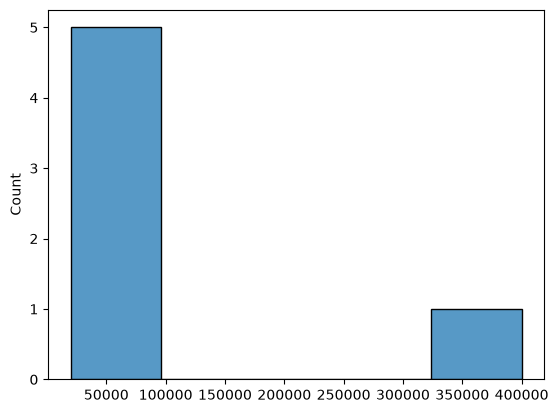

In [24]:
sns.histplot([20000,22000,25000,30000,400000,50000])

In [25]:
pd.DataFrame([20000,22000,25000,30000,400000,500000]).skew()

0    1.054487
dtype: float64

In [26]:
pd.DataFrame(np.log1p([20000,22000,25000,30000,400000,500000])).skew()

0    0.943307
dtype: float64

In [27]:
df["Adm_date"]=pd.DataFrame(['2026-01-12', '2026-02-02', '2026-03-05'])

In [28]:
df["Adm_date"]=pd.to_datetime(df["Adm_date"])

In [29]:
df["Adm_date"].dtypes

dtype('<M8[us]')

In [30]:
df['Adm_date'].dt.year

0    2026.0
1    2026.0
2    2026.0
3       NaN
4       NaN
Name: Adm_date, dtype: float64

In [31]:
df['Adm_date'].dt.month

0    1.0
1    2.0
2    3.0
3    NaN
4    NaN
Name: Adm_date, dtype: float64